<a href="https://colab.research.google.com/github/mrdbourke/pytorch-deep-learning/blob/main/extras/exercises/01_pytorch_workflow_exercises.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 01. PyTorch Workflow Exercise Template

The following is a template for the PyTorch workflow exercises.

It's only starter code and it's your job to fill in the blanks.

Because of the flexibility of PyTorch, there may be more than one way to answer the question.

Don't worry about trying to be *right* just try writing code that suffices the question.

You can see one form of [solutions on GitHub](https://github.com/mrdbourke/pytorch-deep-learning/tree/main/extras/solutions) (but try the exercises below yourself first!).

In [122]:
# Import necessary libraries
import matplotlib.pyplot as plt
import torch
import torch.nn as nn


In [123]:
# Setup device-agnostic code
device = 'cuda' if torch.cuda.is_available() else 'cpu'

## 1. Create a straight line dataset using the linear regression formula (`weight * X + bias`).
  * Set `weight=0.3` and `bias=0.9` there should be at least 100 datapoints total. 
  * Split the data into 80% training, 20% testing.
  * Plot the training and testing data so it becomes visual.

Your output of the below cell should look something like:
```
Number of X samples: 100
Number of y samples: 100
First 10 X & y samples:
X: tensor([0.0000, 0.0100, 0.0200, 0.0300, 0.0400, 0.0500, 0.0600, 0.0700, 0.0800,
        0.0900])
y: tensor([0.9000, 0.9030, 0.9060, 0.9090, 0.9120, 0.9150, 0.9180, 0.9210, 0.9240,
        0.9270])
```

Of course the numbers in `X` and `y` may be different but ideally they're created using the linear regression formula.

In [124]:
# Create the data parameters

## Initialize the Weights
weight = 0.3
bias = 0.9

# Make X and y using linear regression feature
X = torch.arange(start=0, end=1, step=0.01)
y = weight * X + bias

print(f"Number of X samples: {len(X)}")
print(f"Number of y samples: {len(y)}")
print(f"First 10 X & y samples:\nX: {X[:10]}\ny: {y[:10]}")

Number of X samples: 100
Number of y samples: 100
First 10 X & y samples:
X: tensor([0.0000, 0.0100, 0.0200, 0.0300, 0.0400, 0.0500, 0.0600, 0.0700, 0.0800,
        0.0900])
y: tensor([0.9000, 0.9030, 0.9060, 0.9090, 0.9120, 0.9150, 0.9180, 0.9210, 0.9240,
        0.9270])


In [125]:
# Split the data into training and testing
train_length = int(0.8 * (len(X)))

# Train
X_train = X[:train_length]
y_train = y[:train_length]

# Test
X_test = X[train_length:]
y_test = y[train_length:]

len(X_train), len(y_train), len(X_test), len(y_test)

(80, 80, 20, 20)

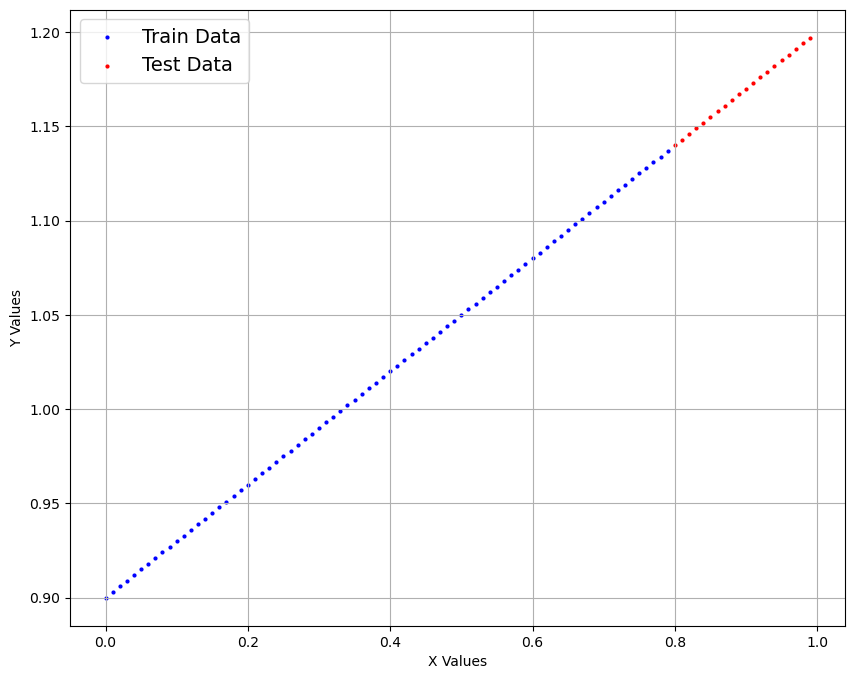

In [126]:
# Plot the training and testing data 
def plot_data_points(train_data = X_train,
                    train_labels=y_train,
                    test_data=X_test,
                    test_labels=y_test,
                    predictions=None
                    ):

    plt.figure(figsize=(10, 8))

    plt.scatter(x=train_data, y=train_labels, c='b', label="Train Data", s=4)

    plt.scatter(x=test_data, y=test_labels, c='r', label="Test Data", s=4)

    if predictions != None:
        plt.scatter(x=test_data, y=predictions, c='g', label="Predictions", s=4)

    plt.legend(prop={'size':14})
    plt.xlabel("X Values")
    plt.ylabel("Y Values")
    plt.grid(visible=True)

    plt.show()

plot_data_points()

## 2. Build a PyTorch model by subclassing `nn.Module`. 
  * Inside should be a randomly initialized `nn.Parameter()` with `requires_grad=True`, one for `weights` and one for `bias`. 
  * Implement the `forward()` method to compute the linear regression function you used to create the dataset in 1. 
  * Once you've constructed the model, make an instance of it and check its `state_dict()`.
  * **Note:** If you'd like to use `nn.Linear()` instead of `nn.Parameter()` you can.

In [127]:
# Build a basic Linear Regression Model

class LinearRegression(nn.Module):
    def __init__(self):
        super().__init__()

        # initialize Parameters (Randomly)
        self.weight = nn.Parameter(torch.rand(1,                    # <- start with random weights (this will get adjusted as the model learns)
                                            dtype=torch.float,
                                            requires_grad=True))    # <- can we update this value with gradient descent?))

        self.bias = nn.Parameter(torch.rand(1,                      # <- start with random weights (this will get adjusted as the model learns)
                                            dtype=torch.float,
                                            requires_grad=True))    # <- can we update this value with gradient descent?))

    # Forward Function Defines the computations in the Model
    def forward(self, x:torch.Tensor) -> torch.Tensor:              # <- "x" is the input data (e.g. training/testing features)
        return self.weight * x + self.bias                          # <- this is the linear regression formula (y = m*x + b)




# Build a basic Linear Regression model V2 (by nn.Linear instead of initializing the weights by hand)
class LinearRegressionV2(nn.Module):
    def __init__(self):
        super().__init__()

        self.layer1 = nn.Linear(in_features=1,                      # input features =1 cause X is a one dimensional tensor of 1 feature
                                out_features=1                      # out features = 1, we need a basic Linear regression model (NN of one neuron, andone layer
                                )


    def forward(self, X:torch.Tensor) -> torch.Tensor:
        return self.layer1(X)


In [128]:
# Instantiate the model and put it to the target device

# instantiate an object Of V1 Class
model_v1 = LinearRegression()
# to device 
model_v1.to(device)


# Instantiate an object of V2 class
model_v2 = LinearRegressionV2()
# to device
model_v2.to(device)


print(f"Model V1 details: {model_v1.state_dict()}")
print(f"Model V1 device: {next(model_v1.parameters()).device}")
print(f"\nModel V2 details: {model_v2.state_dict()}")
print(f"Model V2 device: {next(model_v2.parameters()).device}")

Model V1 details: OrderedDict([('weight', tensor([0.0112], device='cuda:0')), ('bias', tensor([0.4876], device='cuda:0'))])
Model V1 device: cuda:0

Model V2 details: OrderedDict([('layer1.weight', tensor([[-0.6963]], device='cuda:0')), ('layer1.bias', tensor([-0.2263], device='cuda:0'))])
Model V2 device: cuda:0


## 3. Create a loss function and optimizer using `nn.L1Loss()` and `torch.optim.SGD(params, lr)` respectively. 
  * Set the learning rate of the optimizer to be 0.01 and the parameters to optimize should be the model parameters from the model you created in 2.
  * Write a training loop to perform the appropriate training steps for 300 epochs.
  * The training loop should test the model on the test dataset every 20 epochs.

In [129]:
# Create the loss function and optimizer

# Loss
criterion = nn.L1Loss()                     # MAE

# Optimizer
optimizer = torch.optim.SGD(params=model_v2.parameters(), lr=0.01)

In [130]:
print(f"train shape & dim: {X_train, X_train.shape, X_train.ndim}")
print(f"\ntrain labels shape & dim: {y_train, y_train.shape, y_train.ndim}")
print(f"\ntest data shape & dim: {X_test, X_test.shape, X_test.ndim}")
print(f"\ntest labels shape & dim: {y_test, y_test.shape, y_test.ndim}")

train shape & dim: (tensor([0.0000, 0.0100, 0.0200, 0.0300, 0.0400, 0.0500, 0.0600, 0.0700, 0.0800,
        0.0900, 0.1000, 0.1100, 0.1200, 0.1300, 0.1400, 0.1500, 0.1600, 0.1700,
        0.1800, 0.1900, 0.2000, 0.2100, 0.2200, 0.2300, 0.2400, 0.2500, 0.2600,
        0.2700, 0.2800, 0.2900, 0.3000, 0.3100, 0.3200, 0.3300, 0.3400, 0.3500,
        0.3600, 0.3700, 0.3800, 0.3900, 0.4000, 0.4100, 0.4200, 0.4300, 0.4400,
        0.4500, 0.4600, 0.4700, 0.4800, 0.4900, 0.5000, 0.5100, 0.5200, 0.5300,
        0.5400, 0.5500, 0.5600, 0.5700, 0.5800, 0.5900, 0.6000, 0.6100, 0.6200,
        0.6300, 0.6400, 0.6500, 0.6600, 0.6700, 0.6800, 0.6900, 0.7000, 0.7100,
        0.7200, 0.7300, 0.7400, 0.7500, 0.7600, 0.7700, 0.7800, 0.7900]), torch.Size([80]), 1)

train labels shape & dim: (tensor([0.9000, 0.9030, 0.9060, 0.9090, 0.9120, 0.9150, 0.9180, 0.9210, 0.9240,
        0.9270, 0.9300, 0.9330, 0.9360, 0.9390, 0.9420, 0.9450, 0.9480, 0.9510,
        0.9540, 0.9570, 0.9600, 0.9630, 0.9660, 0.9690, 0

In [131]:
# Training loop


# Train model for 300 epochs
epochs = 300

# Send data to target device
X_train = X_train.to(device).unsqueeze(1)
y_train = y_train.to(device).unsqueeze(1)
X_test = X_test.to(device).unsqueeze(1)
y_test = y_test.to(device).unsqueeze(1)

for epoch in range(epochs):
  ### Training

  # Put model in train mode
  model_v2.train()

  # 1. Forward pass
  y_pred = model_v2(X_train)

  # 2. Calculate loss
  loss = criterion(y_pred, y_train)

  # 3. Zero gradients
  optimizer.zero_grad()

  # 4. Backpropagation
  loss.backward()

  # 5. Step the optimizer
  optimizer.step()

  ### Perform testing every 20 epochs
  if epoch % 20 == 0:

    # Put model in evaluation mode and setup inference context 
    model_v2.eval()

    # 1. Forward pass
    y_test_pred = model_v2(X_test)

    # 2. Calculate test loss
    test_loss = criterion(y_test_pred, y_test)

    # Print out what's happening
    print(f"Epoch: {epoch} | Train loss: {loss:.3f} | Test loss: {test_loss:.3f}")

Epoch: 0 | Train loss: 1.520 | Test loss: 2.004
Epoch: 20 | Train loss: 1.289 | Test loss: 1.734
Epoch: 40 | Train loss: 1.057 | Test loss: 1.463
Epoch: 60 | Train loss: 0.826 | Test loss: 1.192
Epoch: 80 | Train loss: 0.595 | Test loss: 0.922
Epoch: 100 | Train loss: 0.364 | Test loss: 0.651
Epoch: 120 | Train loss: 0.154 | Test loss: 0.395
Epoch: 140 | Train loss: 0.095 | Test loss: 0.259
Epoch: 160 | Train loss: 0.082 | Test loss: 0.204
Epoch: 180 | Train loss: 0.075 | Test loss: 0.178
Epoch: 200 | Train loss: 0.068 | Test loss: 0.160
Epoch: 220 | Train loss: 0.061 | Test loss: 0.144
Epoch: 240 | Train loss: 0.054 | Test loss: 0.128
Epoch: 260 | Train loss: 0.048 | Test loss: 0.112
Epoch: 280 | Train loss: 0.041 | Test loss: 0.095


In [132]:
print(f"train shape & dim: {X_train, X_train.shape, X_train.ndim}")
print(f"\ntrain labels shape & dim: {y_train, y_train.shape, y_train.ndim}")
print(f"\ntest data shape & dim: {X_test, X_test.shape, X_test.ndim}")
print(f"\ntest labels shape & dim: {y_test, y_test.shape, y_test.ndim}")

train shape & dim: (tensor([[0.0000],
        [0.0100],
        [0.0200],
        [0.0300],
        [0.0400],
        [0.0500],
        [0.0600],
        [0.0700],
        [0.0800],
        [0.0900],
        [0.1000],
        [0.1100],
        [0.1200],
        [0.1300],
        [0.1400],
        [0.1500],
        [0.1600],
        [0.1700],
        [0.1800],
        [0.1900],
        [0.2000],
        [0.2100],
        [0.2200],
        [0.2300],
        [0.2400],
        [0.2500],
        [0.2600],
        [0.2700],
        [0.2800],
        [0.2900],
        [0.3000],
        [0.3100],
        [0.3200],
        [0.3300],
        [0.3400],
        [0.3500],
        [0.3600],
        [0.3700],
        [0.3800],
        [0.3900],
        [0.4000],
        [0.4100],
        [0.4200],
        [0.4300],
        [0.4400],
        [0.4500],
        [0.4600],
        [0.4700],
        [0.4800],
        [0.4900],
        [0.5000],
        [0.5100],
        [0.5200],
        [0.5300],
        

## 4. Make predictions with the trained model on the test data.
  * Visualize these predictions against the original training and testing data (**note:** you may need to make sure the predictions are *not* on the GPU if you want to use non-CUDA-enabled libraries such as matplotlib to plot).

In [133]:
# Make predictions with the model
with torch.inference_mode():
    model_v2.eval()
    predictions = model_v2(X_test)


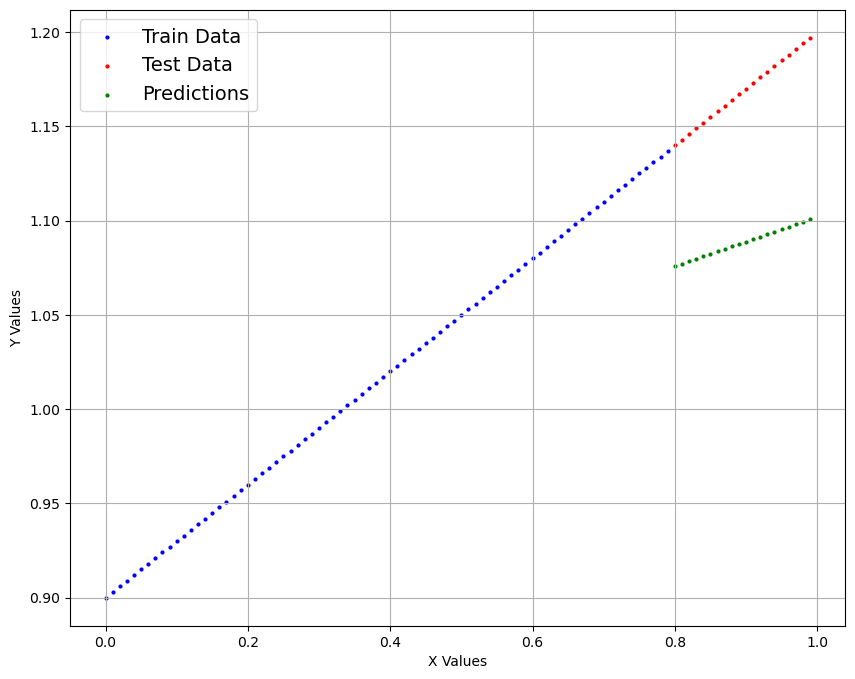

In [134]:
# Plot the predictions (these may need to be on a specific device)
plot_data_points(predictions=predictions.to('cpu'))

## 5. Save your trained model's `state_dict()` to file.
  * Create a new instance of your model class you made in 2. and load in the `state_dict()` you just saved to it.
  * Perform predictions on your test data with the loaded model and confirm they match the original model predictions from 4.

In [138]:
from pathlib import Path

# 1. Create models directory 
MODEL_PATH = Path("models")
MODEL_PATH.mkdir(parents=True, exist_ok=True)

# 2. Create model save path 
MODEL_NAME = "exercise_model.pth" 
MODEL_SAVE_PATH = MODEL_PATH / MODEL_NAME

# 3. Save the model state dict
torch.save(obj=model_v2.state_dict(), f=MODEL_SAVE_PATH)

In [139]:
# Create new instance of model and load saved state dict (make sure to put it on the target device)
loaded_model = LinearRegressionV2()

loaded_model.load_state_dict(torch.load(f=MODEL_SAVE_PATH, weights_only=True))

<All keys matched successfully>

In [141]:
# Make predictions with loaded model and compare them to the previous
loaded_model.to(device)

loaded_model_predictions = loaded_model(X_test)
loaded_model_predictions == predictions

tensor([[True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True]], device='cuda:0')